In [1]:
import pandas as pd
df= pd.read_csv('cs-training.csv')
df = df.drop(columns=["Unnamed: 0"])   # ← NEW: row ID, not a feature
print(df.shape)           # nombre de lignes / colonnes
print(df.info())          # types de données, valeurs non-nulles
print(df["SeriousDlqin2yrs"].value_counts(normalize=True))  # équilibre des classes
df.head(20)

(150000, 11)
<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dty

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
5,0,0.213179,74,0,0.375607,3500.0,3,0,1,0,1.0
6,0,0.305682,57,0,5710.000000,NaN,8,0,3,0,0.0
7,0,0.754464,39,0,0.209940,3500.0,8,0,0,0,0.0
8,0,0.116951,27,0,46.000000,NaN,2,0,0,0,NaN
9,0,0.189169,57,0,0.606291,23684.0,9,0,4,0,2.0


In [2]:
df.describe()    # statistiques (min, max, moyenne...)

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.202690e+05,150000.000000,150000.000000,150000.000000,150000.000000,146076.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.670221e+03,8.452760,0.265973,1.018240,0.240387,0.757222
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.438467e+04,5.145951,4.169304,1.129771,4.155179,1.115086
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.400000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,8.249000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [3]:
df.isnull().sum() # valeurs manquantes par colonne

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

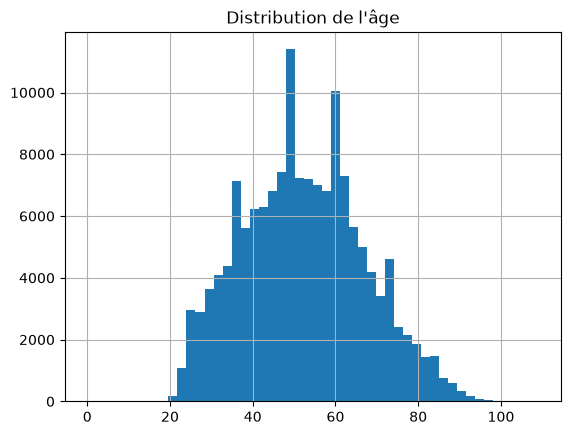

SeriousDlqin2yrs                        1.000000
NumberOfTime30-59DaysPastDueNotWorse    0.125587
NumberOfTimes90DaysLate                 0.117175
NumberOfTime60-89DaysPastDueNotWorse    0.102261
NumberOfDependents                      0.046048
RevolvingUtilizationOfUnsecuredLines   -0.001802
NumberRealEstateLoansOrLines           -0.007038
DebtRatio                              -0.007602
MonthlyIncome                          -0.019746
NumberOfOpenCreditLinesAndLoans        -0.029669
age                                    -0.115386
Name: SeriousDlqin2yrs, dtype: float64


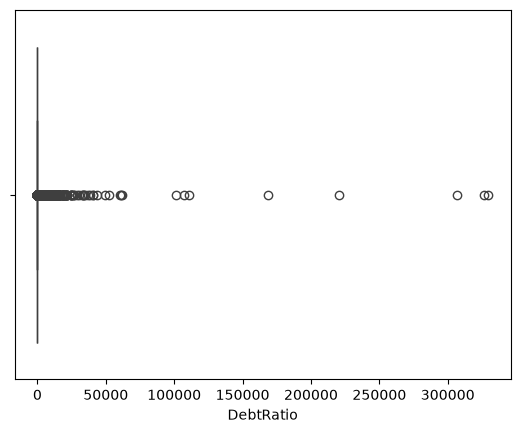

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribution de l'âge
df["age"].hist(bins=50)
plt.title("Distribution de l'âge")
plt.show()

# Corrélation avec la cible
correlations = df.corr()["SeriousDlqin2yrs"].sort_values(ascending=False)
print(correlations)

# Boxplot pour repérer les outliers
sns.boxplot(x=df["DebtRatio"])
plt.show()

In [5]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["SeriousDlqin2yrs"])
y = df["SeriousDlqin2yrs"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

=== RevolvingUtilizationOfUnsecuredLines ===
count    120000.000000
mean          6.128916
std         253.361490
min           0.000000
25%           0.029593
50%           0.153318
75%           0.557832
max       50708.000000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64
Valeurs manquantes: 0
Valeurs uniques (si peu nombreuses): 100929


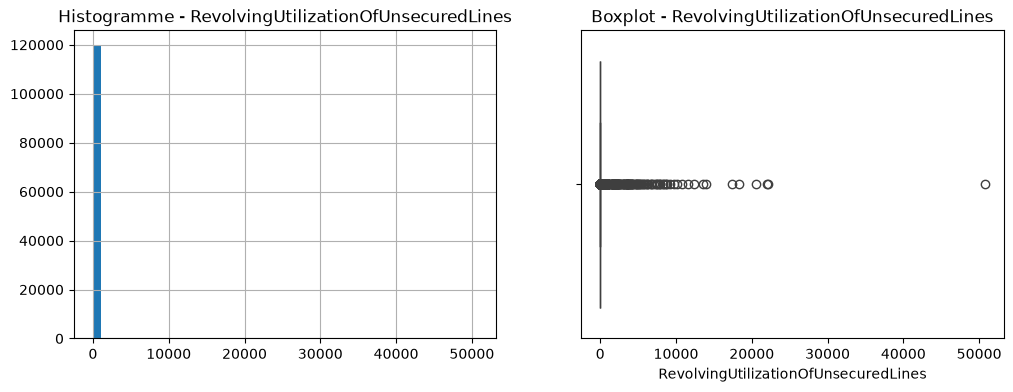

=== age ===
count    120000.000000
mean         52.287842
std          14.771274
min           0.000000
25%          41.000000
50%          52.000000
75%          63.000000
max         109.000000
Name: age, dtype: float64
Valeurs manquantes: 0
Valeurs uniques (si peu nombreuses): 84


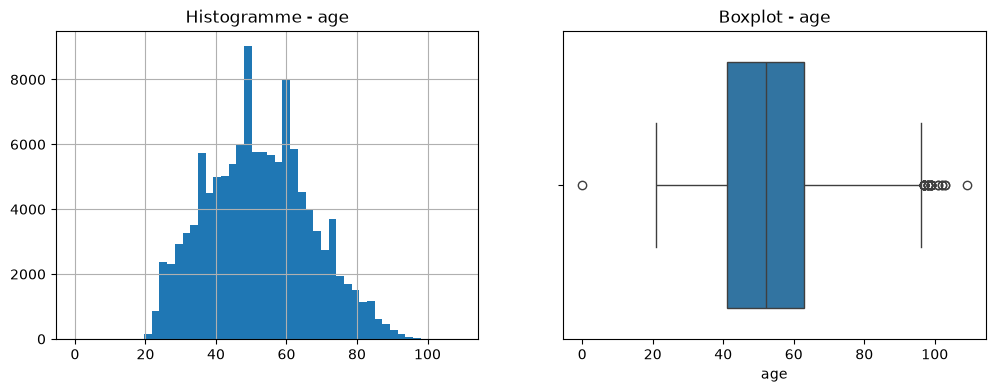

=== NumberOfTime30-59DaysPastDueNotWorse ===
count    120000.000000
mean          0.420075
std           4.182138
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          98.000000
Name: NumberOfTime30-59DaysPastDueNotWorse, dtype: float64
Valeurs manquantes: 0
Valeurs uniques (si peu nombreuses): 16


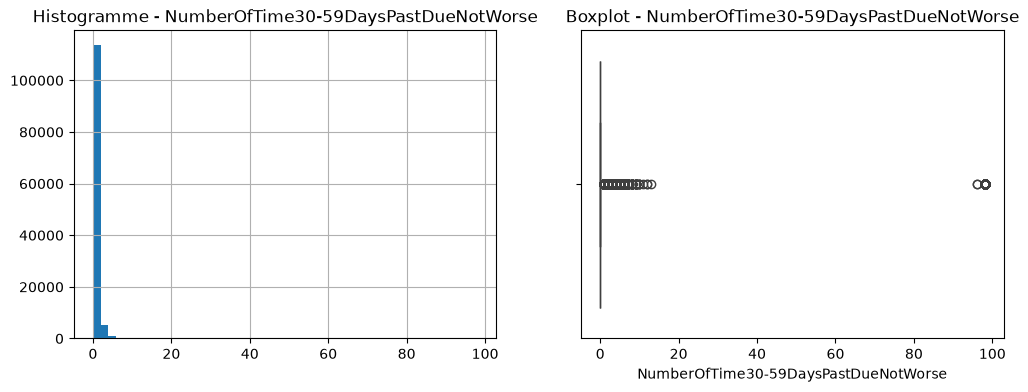

=== DebtRatio ===
count    120000.000000
mean        352.271245
std        2093.709509
min           0.000000
25%           0.175330
50%           0.366194
75%           0.860833
max      329664.000000
Name: DebtRatio, dtype: float64
Valeurs manquantes: 0
Valeurs uniques (si peu nombreuses): 93157


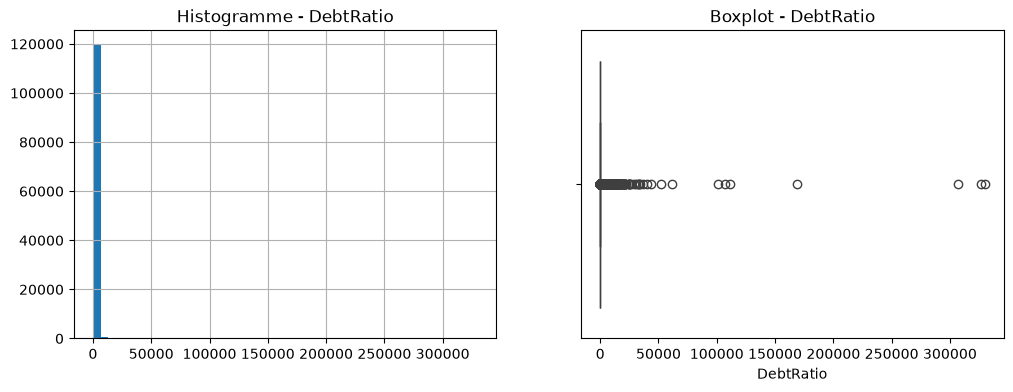

=== MonthlyIncome ===
count    9.632500e+04
mean     6.651507e+03
std      1.454118e+04
min      0.000000e+00
25%      3.400000e+03
50%      5.390000e+03
75%      8.238000e+03
max      3.008750e+06
Name: MonthlyIncome, dtype: float64
Valeurs manquantes: 23675
Valeurs uniques (si peu nombreuses): 12678


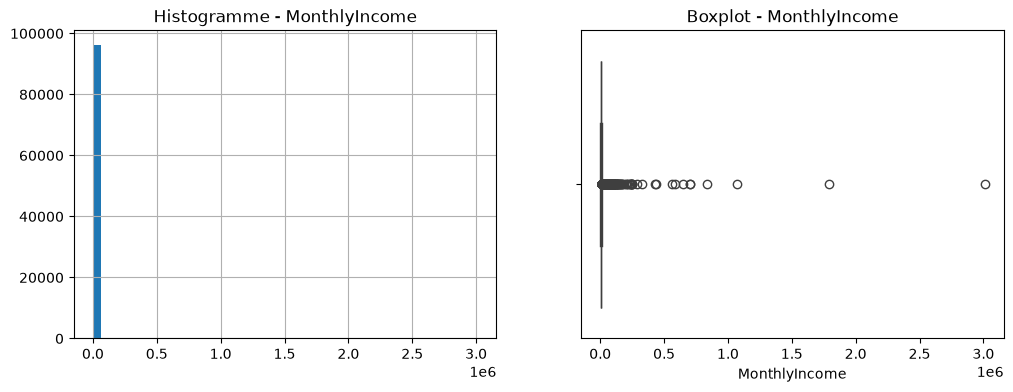

=== NumberOfOpenCreditLinesAndLoans ===
count    120000.000000
mean          8.465692
std           5.161693
min           0.000000
25%           5.000000
50%           8.000000
75%          11.000000
max          58.000000
Name: NumberOfOpenCreditLinesAndLoans, dtype: float64
Valeurs manquantes: 0
Valeurs uniques (si peu nombreuses): 58


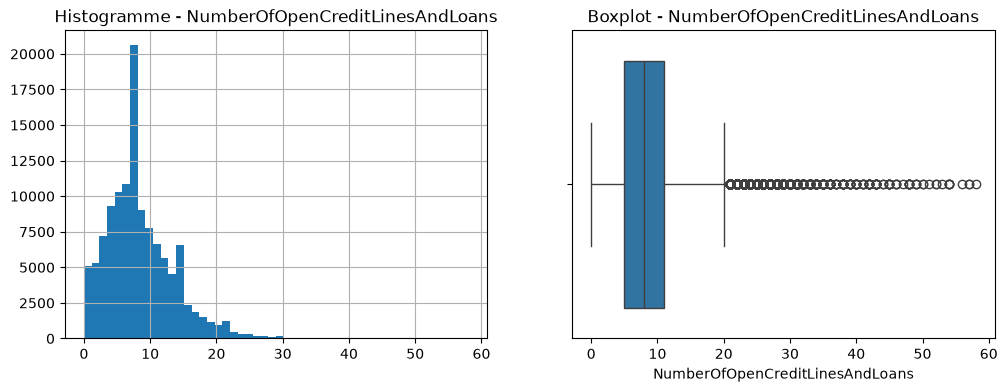

=== NumberOfTimes90DaysLate ===
count    120000.000000
mean          0.264942
std           4.158242
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          98.000000
Name: NumberOfTimes90DaysLate, dtype: float64
Valeurs manquantes: 0
Valeurs uniques (si peu nombreuses): 19


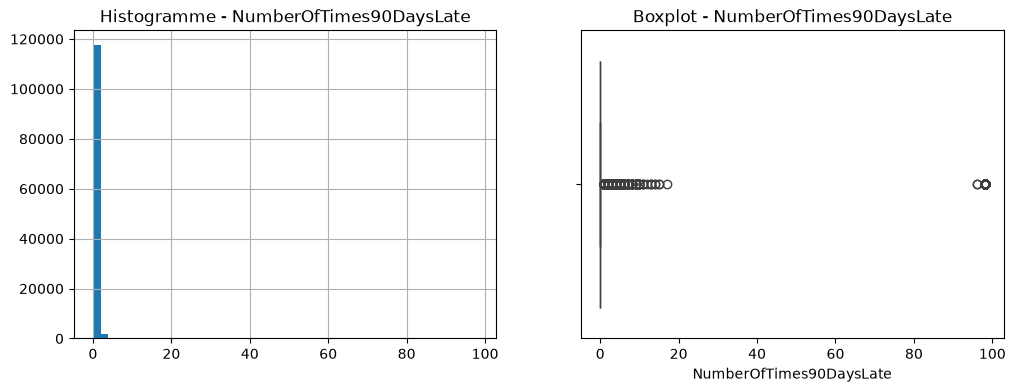

=== NumberRealEstateLoansOrLines ===
count    120000.000000
mean          1.018167
std           1.133055
min           0.000000
25%           0.000000
50%           1.000000
75%           2.000000
max          54.000000
Name: NumberRealEstateLoansOrLines, dtype: float64
Valeurs manquantes: 0
Valeurs uniques (si peu nombreuses): 28


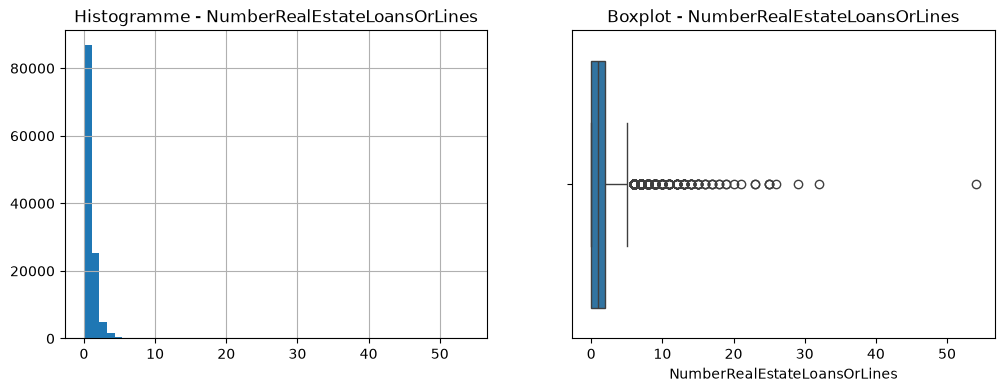

=== NumberOfTime60-89DaysPastDueNotWorse ===
count    120000.000000
mean          0.239858
std           4.144569
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          98.000000
Name: NumberOfTime60-89DaysPastDueNotWorse, dtype: float64
Valeurs manquantes: 0
Valeurs uniques (si peu nombreuses): 13


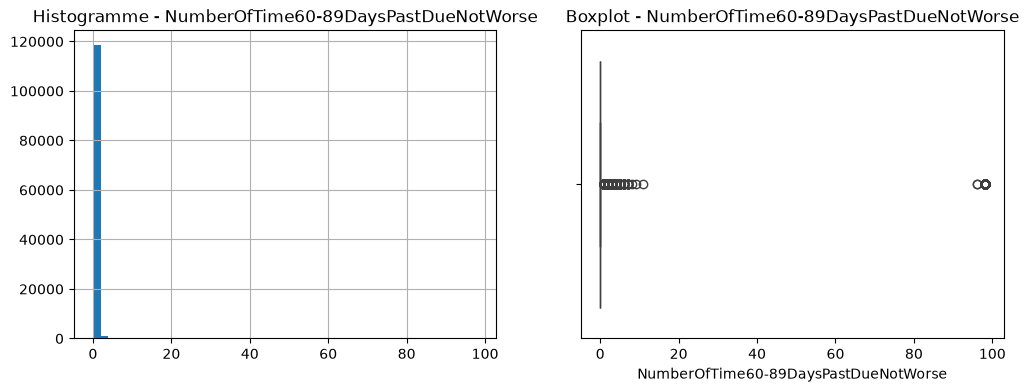

=== NumberOfDependents ===
count    116872.000000
mean          0.757333
std           1.115337
min           0.000000
25%           0.000000
50%           0.000000
75%           1.000000
max          20.000000
Name: NumberOfDependents, dtype: float64
Valeurs manquantes: 3128
Valeurs uniques (si peu nombreuses): 13


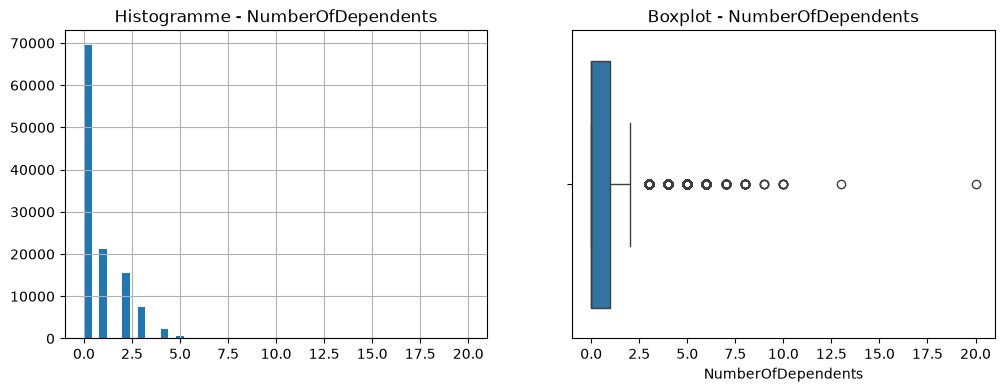

In [6]:
def explore_column(df, col):
    print(f"=== {col} ===")
    print(df[col].describe())
    print(f"Valeurs manquantes: {df[col].isnull().sum()}")
    print(f"Valeurs uniques (si peu nombreuses): {df[col].nunique()}")
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    df[col].hist(bins=50, ax=axes[0])
    axes[0].set_title(f"Histogramme - {col}")
    sns.boxplot(x=df[col], ax=axes[1])
    axes[1].set_title(f"Boxplot - {col}")
    plt.show()

for col in X_train.columns:
    explore_column(X_train, col)

## nettoyage des données

In [7]:
print((X_train["age"] < 18).sum()) # → 1 seule ligne avec age = 0
#supprimer les lignes avec age < 18 (age = 0)
mask = X_train["age"] >= 18
print("rows removed:", (~mask).sum())
X_train, y_train = X_train[mask], y_train[mask]

1
rows removed: 1


In [ ]:
# Set up Logistic Regression and XGBoost pipelines with appropriate preprocessing,
# define credit-scoring evaluation metrics (ROC-AUC, Gini, PR-AUC, KS),
# and configure MLflow to track the experiments and model results.
import numpy as np
import matplotlib.pyplot as plt
import mlflow, mlflow.sklearn
from mlflow.models import infer_signature
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_score, recall_score, confusion_matrix)
from xgboost import XGBClassifier
from preprocessing import CreditCleaner

# Logistic regression needs scaling -> scaler lives INSIDE its pipeline
lr_pipe = Pipeline([
    ("prep", CreditCleaner()),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)),
])

# XGBoost: no scaling, so SHAP will show real values (age = 45, not -0.3)
scale = (y_train == 0).sum() / (y_train == 1).sum()
xgb_pipe = Pipeline([
    ("prep", CreditCleaner()),
    ("model", XGBClassifier(scale_pos_weight=scale, eval_metric="aucpr", random_state=42)),
])

def rank_metrics(y_true, proba):
    auc = roc_auc_score(y_true, proba)
    fpr, tpr, _ = roc_curve(y_true, proba)
    return {"roc_auc": auc, "gini": 2 * auc - 1,
            "pr_auc": average_precision_score(y_true, proba),
            "ks": float(np.max(tpr - fpr))}

mlflow.set_experiment("credit_scoring")   # new experiment: the old runs used the flawed setup

2026/09/29 14:15:43 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/09/29 14:15:43 INFO mlflow.store.db.utils: Updating database tables
2026/09/29 14:15:45 INFO mlflow.tracking.fluent: Experiment with name 'credit_scoring_v2' does not exist. Creating a new experiment.


<Experiment: artifact_location='file:c:/Users/Lenovo/Desktop/Nouveau dossier/mlruns/1', creation_time=1790687745667, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1790687745667, lifecycle_stage='active', name='credit_scoring_v2', tags={}, trace_location=None, workspace='default'>

## Logistic regression
### baseline model

In [11]:
with mlflow.start_run(run_name="logistic_regression"):
    lr_pipe.fit(X_train, y_train)
    p_lr = lr_pipe.predict_proba(X_test)[:, 1]
    m = rank_metrics(y_test, p_lr)
    print(m)

    mlflow.log_params({"model": "logistic_regression", "class_weight": "balanced"})
    mlflow.log_metrics(m)
    mlflow.sklearn.log_model(lr_pipe, name="model", input_example=X_test.head(3),
                             signature=infer_signature(X_test, p_lr),
                             serialization_format="cloudpickle")

{'roc_auc': 0.8595984409399791, 'gini': 0.7191968818799581, 'pr_auc': 0.38904450118969475, 'ks': 0.5609900948646422}


c:\Users\Lenovo\Desktop\Nouveau dossier\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/09/29 17:09:23 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute 

## XGBoost

In [12]:
param_dist = {
    "model__max_depth": [3, 4, 5, 6, 8],
    "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "model__n_estimators": [100, 200, 300],
    "model__min_child_weight": [1, 3, 5],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
}
search = RandomizedSearchCV(xgb_pipe, param_dist, n_iter=30, scoring="average_precision",
                            cv=5, random_state=42, n_jobs=-1)
search.fit(X_train, y_train)
best_pipe = search.best_estimator_

print("Best params:", search.best_params_)
print("CV PR-AUC:", search.best_score_)

Best params: {'model__subsample': 1.0, 'model__n_estimators': 300, 'model__min_child_weight': 3, 'model__max_depth': 4, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.7}
CV PR-AUC: 0.40108331367480554


In [15]:
# 1. Calibrate: makes the output a real probability
calibrated = CalibratedClassifierCV(clone(best_pipe), method="isotonic", cv=3)

# 2. Choose the threshold on out-of-fold TRAIN predictions (never on test)
oof = cross_val_predict(calibrated, X_train, y_train, cv=3, method="predict_proba")[:, 1]
calibrated.fit(X_train, y_train)

# 3. Business costs: approving a defaulter is worse than rejecting a good client
COST_FN, COST_FP = 5, 1   # ← assumption, adjust to your story
thresholds = np.linspace(0.02, 0.6, 117)
costs = []
for t in thresholds:
    pred = oof >= t
    fn = ((~pred) & (y_train == 1)).sum()
    fp = (pred & (y_train == 0)).sum()
    costs.append(COST_FN * fn + COST_FP * fp)
best_t = float(thresholds[int(np.argmin(costs))])
print(f"threshold (empirical) = {best_t:.3f} | theory = {COST_FP/(COST_FP+COST_FN):.3f}")

base_rate = float(y_train.mean())
def risk_level(p):
    return "low" if p < base_rate else ("medium" if p < best_t else "high")

threshold (empirical) = 0.165 | theory = 0.167


{'roc_auc': 0.8697426820517914, 'gini': 0.7394853641035828, 'pr_auc': 0.4066705330757336, 'ks': 0.5845803423215492, 'brier': 0.048669471512555, 'precision': 0.35647279549718575, 'recall': 0.5685785536159601, 'test_cost': 6383}
[[25937  2058]
 [  865  1140]]
mean predicted: 0.06704995309668496 | real default rate: 0.06683333333333333


c:\Users\Lenovo\Desktop\Nouveau dossier\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/09/29 17:43:31 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute 

2026/09/29 17:43:53 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
c:\Users\Lenovo\Desktop\Nouveau dossier\.venv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missin

Run ID: 11ebc65482ff4453a27f8935b3205edf


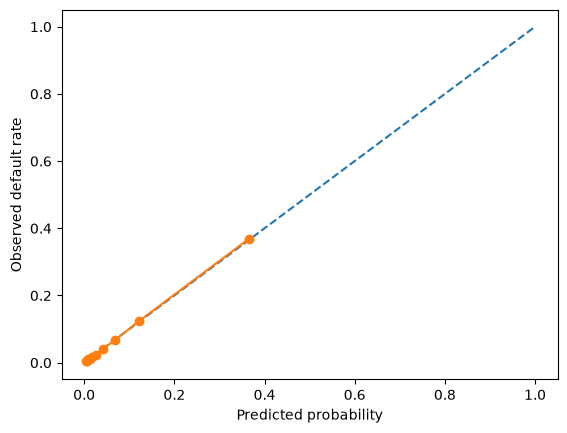

In [16]:
proba = calibrated.predict_proba(X_test)[:, 1]
pred = (proba >= best_t).astype(int)

m = rank_metrics(y_test, proba)
m["brier"] = brier_score_loss(y_test, proba)
m["precision"] = precision_score(y_test, pred)
m["recall"] = recall_score(y_test, pred)
m["test_cost"] = int(COST_FN * ((pred == 0) & (y_test == 1)).sum()
                     + COST_FP * ((pred == 1) & (y_test == 0)).sum())
print(m)
print(confusion_matrix(y_test, pred))
print("mean predicted:", proba.mean(), "| real default rate:", y_test.mean())

frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10, strategy="quantile")
fig, ax = plt.subplots()
ax.plot([0, 1], [0, 1], "--"); ax.plot(mean_pred, frac_pos, marker="o")
ax.set_xlabel("Predicted probability"); ax.set_ylabel("Observed default rate")

with mlflow.start_run(run_name="xgboost_tuned_calibrated") as run:
    mlflow.log_params({k.replace("model__", ""): v for k, v in search.best_params_.items()})
    mlflow.log_params({"calibration": "isotonic", "threshold": best_t,
                       "cost_fn": COST_FN, "cost_fp": COST_FP})
    mlflow.log_metric("cv_pr_auc", search.best_score_)
    mlflow.log_metrics(m)
    mlflow.log_figure(fig, "calibration_curve.png")
    # served model (calibrated probabilities)
    mlflow.sklearn.log_model(calibrated, name="model", input_example=X_test.head(3),
                             signature=infer_signature(X_test, proba),
                             serialization_format="cloudpickle")
    # model used for SHAP explanations
    mlflow.sklearn.log_model(best_pipe, name="explain_pipeline", input_example=X_test.head(3),
                             serialization_format="cloudpickle")
    print("Run ID:", run.info.run_id)

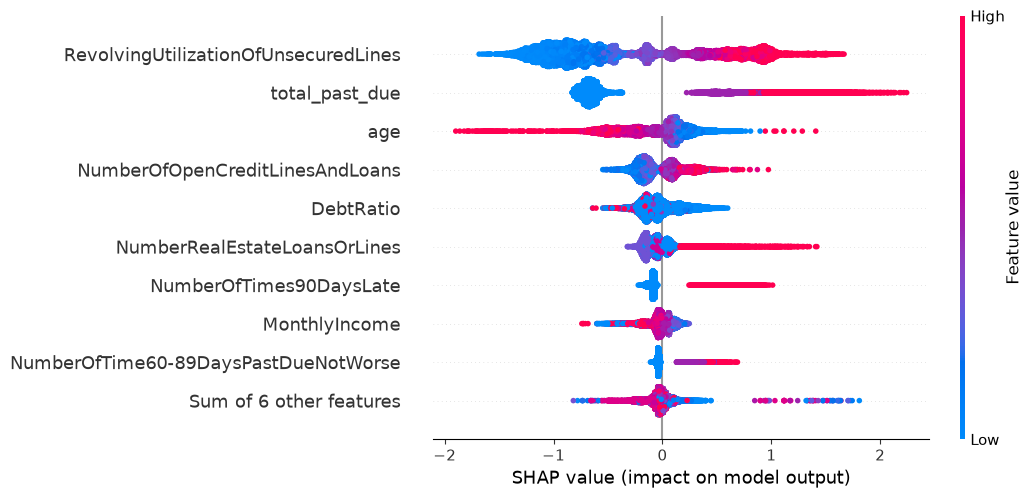

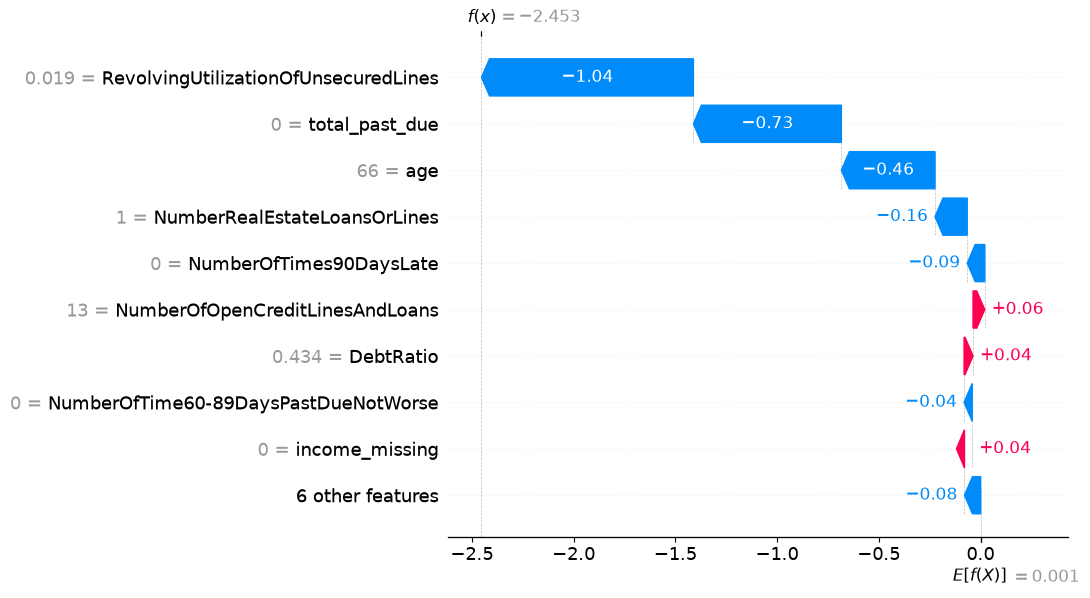

In [17]:
import shap

X_test_prep = best_pipe.named_steps["prep"].transform(X_test)
explainer = shap.TreeExplainer(best_pipe.named_steps["model"])
shap_values = explainer(X_test_prep)

plt.figure(); shap.plots.beeswarm(shap_values, show=False)      # global view
plt.gcf().savefig("shap_beeswarm.png", bbox_inches="tight")
plt.figure(); shap.plots.waterfall(shap_values[0], show=False)  # one client
plt.gcf().savefig("shap_waterfall.png", bbox_inches="tight")

# log the plots into the same MLflow run
with mlflow.start_run(run_id=run.info.run_id):
    mlflow.log_artifact("shap_beeswarm.png")
    mlflow.log_artifact("shap_waterfall.png")

In [18]:
# Does missing income change what DebtRatio means?
print(X_train.groupby(X_train["MonthlyIncome"].isna())["DebtRatio"].describe())

# Do the engineered features help? Compare CV PR-AUC with and without them
from sklearn.model_selection import cross_val_score
for flag in [True, False]:
    p = clone(best_pipe).set_params(prep__add_features=flag)
    print(flag, cross_val_score(p, X_train, y_train, cv=5, scoring="average_precision").mean())

                 count         mean          std  min         25%  \
MonthlyIncome                                                       
False          96324.0    25.424795   317.512628  0.0    0.143951   
True           23675.0  1682.092122  4427.909568  0.0  123.000000   

                       50%          75%       max  
MonthlyIncome                                      
False             0.296107     0.482756   25801.0  
True           1163.000000  2384.000000  329664.0  
True 0.40108331367480554
False 0.39927728169693133


In [19]:
from mlflow import MlflowClient

client = MlflowClient()
run_id = run.info.run_id
# If you restarted the kernel, look the run up instead:
# runs = mlflow.search_runs(experiment_names=["credit_scoring"],
#         filter_string="tags.mlflow.runName = 'xgboost_tuned_calibrated'",
#         order_by=["start_time DESC"])
# run_id = runs.iloc[0]["run_id"]

config = {
    "threshold": best_t,
    "base_rate": base_rate,
    "cost_fn": COST_FN,
    "cost_fp": COST_FP,
    "input_features": list(X_train.columns),   # the 10 raw columns the API must receive
}

with mlflow.start_run(run_id=run_id):
    mlflow.log_dict(config, "config.json")
    mlflow.log_metric("baseline_cost_approve_all", int(COST_FN * y_test.sum()))

# Register both models and mark them as the current "champion"
for artifact, name in [("model", "credit_scoring"),
                       ("explain_pipeline", "credit_scoring_explainer")]:
    mv = mlflow.register_model(f"runs:/{run_id}/{artifact}", name)
    client.set_registered_model_alias(name, "champion", mv.version)
    print(name, "-> version", mv.version)

# Quick test: load exactly like the API will
served = mlflow.sklearn.load_model("models:/credit_scoring@champion")
print(served.predict_proba(X_test.head(3))[:, 1])

Successfully registered model 'credit_scoring'.
2026/09/29 19:46:18 WARNING mlflow.tracking._model_registry.fluent: Run with id 11ebc65482ff4453a27f8935b3205edf has no artifacts at artifact path 'model', registering model based on models:/m-9a92ddeb3551454eab905c0a3a650b7d instead
Created version '1' of model 'credit_scoring'.
Successfully registered model 'credit_scoring_explainer'.
2026/09/29 19:46:18 WARNING mlflow.tracking._model_registry.fluent: Run with id 11ebc65482ff4453a27f8935b3205edf has no artifacts at artifact path 'explain_pipeline', registering model based on models:/m-f311aa8f00d74dbcaf960f87bfee9ec3 instead
Created version '1' of model 'credit_scoring_explainer'.


credit_scoring -> version 1
credit_scoring_explainer -> version 1
[0.00642873 0.02373798 0.00425277]


Both models are now at version 1. Next month, if you retrain and get a better model, you register it as version 2. The API still serves version 1 until you move the champion alias to version 2. You can move it back if the new model misbehaves, and the API code never changes. That's the MLOps benefit.

**credit_scoring** is the model that makes predictions. You give it a raw applicant (10 columns) and it returns a calibrated default probability, like 0.18.

**credit_scoring_explainer** is the same pipeline before calibration. It exists for SHAP. SHAP's TreeExplainer needs direct access to the XGBoost trees, and inside the calibrated wrapper those trees are buried in several internal copies. So we keep an unwrapped copy just for explanations.